# code_037 · Units of observation and target design

**Book:** section 8.1. A dataset-construction laboratory using invented structural-monitoring records. Prerequisites: Python arrays, tables and Chapter 7's information boundaries. Restart and run all cells. Every import, helper and input is here; no ordinary-run files, network, credentials, GPU or private helper are required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_08_GUIDE.md), [run evidence](../CHAPTER_08_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_037).

Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0, CPU. Allow one minute to execute and 30–60 minutes to interpret. These are scoped data-contract experiments rather than exhaustive estimator API studies. Construction identities have no training/test interpretation. The sampling laboratory alone fits two fixed constant predictors and protects an independent final population. No engineering reliability or causal maintenance conclusion follows.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=837;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 837


<a id="contract"></a>
## A member-week is an example; a report is evidence

Eighty members each have six candidate weekly cutoffs, days 14,21,28,35,42,49. The target is any recorded finding event in (cutoff,cutoff+14], not a first-event hazard. Members remain eligible after earlier findings; a first-event analysis would require a different risk set. This toy generator supplies at most one event per member. Follow-up ends between days 40 and 90; no-event members have an internal sentinel 999 that never becomes a model feature. Event reports arrive 3–10 days later. A complete negative is available only after the entire horizon has been observed and the maximum ten-day reporting lag has passed. Observed positives can be resolved earlier once their report arrives.

Extraction day is a separate clock. Preserve the member and cutoff for pending/censored examples. Event-at-cutoff is excluded; event-at-horizon-end is included. Candidate construction uses follow-up availability at cutoff, never an eventual event as an input. The result is a construction audit, not a predictive model or independent-row sample.


In [2]:
M=80;members=np.arange(M);cutoffs=np.array([14,21,28,35,42,49]);H=14;MAX_LAG=10
has_event=rng.random(M)<.55;event=np.where(has_event,rng.integers(15,91,M),999);follow=rng.integers(40,91,M);arrival=event+rng.integers(3,11,M)
cases=pd.MultiIndex.from_product([members,cutoffs],names=['member_id','cutoff_day']).to_frame(index=False)
cases=cases[cases.cutoff_day<=follow[cases.member_id]].copy();cases['horizon_end']=cases.cutoff_day+H
assert not cases.duplicated(['member_id','cutoff_day']).any()
assert not (np.array([14,28])>14).all() and ((np.array([14,28])>14)&(np.array([14,28])<=28)).tolist()==[False,True]
def label_table(extract):
 out=cases.copy();i=out.member_id.to_numpy();t=out.cutoff_day.to_numpy();end=out.horizon_end.to_numpy()
 in_window=(event[i]>t)&(event[i]<=end);observed_positive=in_window&(event[i]<=follow[i])
 positive=observed_positive&(arrival[i]<=extract)
 negative=(~in_window)&(follow[i]>=end)&(extract>=end+MAX_LAG)
 out['label']=pd.array(np.where(positive,1,np.where(negative,0,np.nan)),dtype='Int64')
 out['status']=np.where(positive,'positive',np.where(negative,'negative',np.where(follow[i]<end,'censored','pending')))
 return out
labels=label_table(60);assert set(labels.status)<={'positive','negative','censored','pending'}
assert labels.loc[labels.status.isin(['censored','pending']),'label'].isna().all()
assert labels.loc[labels.status=='negative','horizon_end'].max()+MAX_LAG<=60
assert set(labels.columns)=={'member_id','cutoff_day','horizon_end','label','status'}
RESULTS['candidate_examples']=len(cases);RESULTS['members']=M;RESULTS['day60_status_counts']={k:int(v) for k,v in labels.status.value_counts().items()}
display(labels.head(10))


,member_id,cutoff_day,horizon_end,label,status
0,0,14,28,0,negative
1,0,21,35,0,negative
2,0,28,42,0,negative
3,0,35,49,0,negative
4,0,42,56,<NA>,pending
5,0,49,63,<NA>,pending
6,1,14,28,0,negative
7,1,21,35,0,negative
8,1,28,42,0,negative
9,1,35,49,0,negative


<a id="clocks"></a>
## Interpret clocks and dependence

A positive report can settle a target before the window closes. A negative needs complete follow-up and reporting maturity. The timeline below uses explicitly invented day values, separate from the random panel: cutoff 21, horizon end 35, finding event 30, report day 38 and follow-up day 33. The positive is observed before follow-up ends but not known at extraction 35. A second overlapping weekly example can share the same event; row count is not independent-member count.


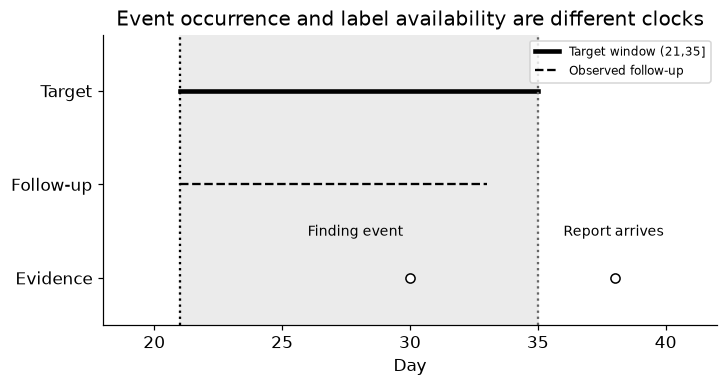

In [3]:
fig,ax=plt.subplots(figsize=(6.5,3.4));ax.axvspan(21,35,color='.92');ax.plot([21,35],[2,2],'k-',lw=3,label='Target window (21,35]');ax.plot([21,33],[1,1],'k--',label='Observed follow-up');ax.scatter([30,38],[0,0],marker='o',facecolors='white',edgecolors='black');ax.annotate('Finding event',xy=(30,0),xytext=(26,.45),fontsize=9);ax.annotate('Report arrives',xy=(38,0),xytext=(36,.45),fontsize=9);ax.axvline(21,color='black',ls=':');ax.axvline(35,color='.4',ls=':');ax.set(xlim=(18,42),ylim=(-.5,2.6),yticks=[0,1,2],yticklabels=['Evidence','Follow-up','Target'],xlabel='Day',title='Event occurrence and label availability are different clocks');ax.legend(fontsize=8,loc='upper right');plt.show()
shared=0
for i in members:
 shared+=int(np.sum((event[i]>cutoffs)&(event[i]<=cutoffs+H))>1)
assert shared>0;RESULTS['members_with_event_in_multiple_windows']=shared


<a id="maturity"></a>
## Extraction time changes the labelled dataset

Predict before running: should a later extract create new cases, or resolve labels on existing candidate keys? Here the candidate set stays fixed. A censored negative cannot be recovered by waiting for uploads after follow-up ended. Pending reports may resolve. Filling every unknown with zero creates a different, unsupported target. Complete-case prevalence also describes the resolved subset, not automatically the original panel.


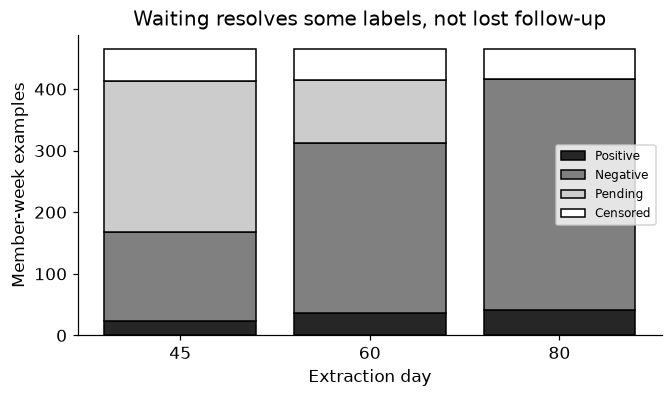

In [4]:
extracts=[45,60,80];counts=[]
for d in extracts:
 a=label_table(d);counts.append([int((a.status==s).sum()) for s in ['positive','negative','pending','censored']]);assert a[['member_id','cutoff_day']].equals(cases[['member_id','cutoff_day']])
counts=np.array(counts);assert np.all(np.diff(counts[:,:2].sum(1))>=0)
fig,ax=plt.subplots(figsize=(6,3.5));bottom=np.zeros(3)
for j,(name,shade) in enumerate(zip(['Positive','Negative','Pending','Censored'],['.15','.5','.8','white'])):
 ax.bar(np.arange(3),counts[:,j],bottom=bottom,color=shade,edgecolor='black',label=name);bottom+=counts[:,j]
ax.set(xticks=np.arange(3),xticklabels=extracts,xlabel='Extraction day',ylabel='Member-week examples',title='Waiting resolves some labels, not lost follow-up');ax.legend(fontsize=8);plt.show()
RESULTS['resolved_prevalence_day60']=float(labels.label.dropna().mean());RESULTS['unsupported_zero_filled_prevalence_day60']=float(labels.label.fillna(0).mean());RESULTS['resolved_counts_by_extract']={str(d):int(row[:2].sum()) for d,row in zip(extracts,counts)}
assert labels.label.isna().any() and labels.label.notna().any()


<a id="exercises"></a>
## Exercises, hints and limitations

1. Change horizon 14 to 28 days; predict how window overlap and outcome maturity change before running.
2. Specify a first-event risk set using history actually known at cutoff; explain how unreported earlier events complicate it.
3. Reduce follow-up preferentially for difficult members. Explain why complete cases no longer represent the same population.
4. Define a building-grouped and chronological future model assessment; never split these overlapping rows as independent evidence.

**Hints:** inclusion, outcome definition, event observation, report arrival and extraction are separate decisions. The event process and maximum reporting lag are stipulated here, not estimated. No survival estimator or censoring correction has been validated by this lab. Retain unresolved state rather than inventing negative labels.


In [5]:
summary={'example_id':'code_037','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['entity cutoff and horizon form the example key', 'closed-right target window', 'censored versus delayed versus resolved outcomes', 'unknown labels are not negatives', 'repeated units and overlapping horizons'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["entity cutoff and horizon form the example key", "closed-right target window", "censored versus delayed versus resolved outcomes", "unknown labels are not negatives", "repeated units and overlapping horizons"], "elapsed_seconds": 0.134, "example_id": "code_037", "hardware": "Darwin arm64 CPU", "results": {"candidate_examples": 465, "day60_status_counts": {"censored": 51, "negative": 276, "pending": 102, "positive": 36}, "members": 80, "members_with_event_in_multiple_windows": 21, "resolved_counts_by_extract": {"45": 168, "60": 312, "80": 416}, "resolved_prevalence_day60": 0.11538461538461539, "unsupported_zero_filled_prevalence_day60": 0.07741935483870968}, "seed": 837, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
